# Supporting Figure S1

![Full Figure](../figures/suppS1_FULL.png)

## Code for Supporting Figure S1: dataset reconstruction and alignment

**Goal:** Document errors in the published Akrami dataset and quantify differences after reconstruction and session alignment.

| Panel | Content | Status |
|---|---|---|
| A | Example learning histories (violations end ~session 200) | coded |
| B | State-machine schematic (timeout mislabeled as violation) | schematic (layout) |
| C | W089 hit-rate alignment (old vs new) | coded |
| D | W089 trial-count alignment (old vs new; line at session 200) | coded |
| E | $\Delta$ sessions (new − old) | coded |
| F | $\Delta$ trials/session (new_no_touts − old) | coded |
| G | $\Delta$ violation/session (×100; new_no_touts − old) | coded |

Summaries from [`scripts/prepare_alignment_summary.py`](../scripts/prepare_alignment_summary.py). Panels C–D reuse the W089 mega-fig hit-rate / trial-count logic from `DatasetVisualizer` (`violations-multinomial`). Delta panels use the 16 manuscript animals (`ANIMAL_IDS`).

**Outputs:** `figures/suppS1a_example_animals.png`, `figures/suppS1c_hit_alignment.png`, `figures/suppS1d_trial_alignment.png`, `figures/suppS1e_delta_sessions.png`, `figures/suppS1f_delta_trials.png`, and `figures/suppS1g_delta_violations.png`.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from violations_glm.config import (
    ANIMAL_IDS,
    HIT_COLOR,
    NEW_DATASET_COLOR,
    N_SESSION_COLOR,
    N_TRIAL_COLOR,
    OLD_DATASET_COLOR,
    VIOLATION_COLOR,
)
from violations_glm.io import (
    load_alignment_dataset_comparison,
    load_alignment_dataset_counts,
    load_alignment_deltas,
    load_alignment_example_curves,
    load_alignment_example_sessions,
    load_alignment_summary,
)
from violations_glm.plotting import configure_publication_dpi, save_figure

configure_publication_dpi()
sns.set_context(
    "notebook",
    rc={
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "axes.titleweight": "bold",
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
        "legend.fontsize": 14,
    },
)

In [2]:
print(list(ANIMAL_IDS))

alignment_summary = load_alignment_summary()
deltas = load_alignment_deltas()
deltas = deltas.loc[deltas["animal_id"].isin(ANIMAL_IDS)].copy()
deltas["animal_id"] = pd.Categorical(
    deltas["animal_id"], categories=list(ANIMAL_IDS), ordered=True
)
deltas = deltas.sort_values("animal_id").reset_index(drop=True)

example_animals_df = load_alignment_example_sessions()
alignment_curves = load_alignment_example_curves()
dataset_comparison = load_alignment_dataset_comparison()
dataset_counts = load_alignment_dataset_counts()

alignment_summary.head()

['W051', 'W060', 'W065', 'W066', 'W068', 'W072', 'W073', 'W074', 'W075', 'W078', 'W080', 'W081', 'W083', 'W088', 'W089', 'W094']


,animal_id,source,max_trial,align_session,n_sessions,n_trials_per_session,session_avg_violation,session_avg_violation_stage_4
0,W051,new,446.0,61.0,604,163.298013,0.155001,0.136250
1,W051,old,443.0,61.0,590,149.939104,0.183063,0.166728
2,W051,new_no_touts,NaN,NaN,599,161.646077,0.177480,0.163597
3,W051,old_only_viols,NaN,NaN,196,159.599490,0.185865,0.170108
4,W060,new,479.0,67.0,492,158.085366,0.153755,0.119455


## Panel A — Example animals (public dataset; violations ending)

Twenty-one-session rolling means of hit and violation rate for W065, W068, and W089 from the public Akrami `rat_behavior` table. Stage shading skips stage 2; violation annotation ends near session 200.


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS1a_example_animals.png')

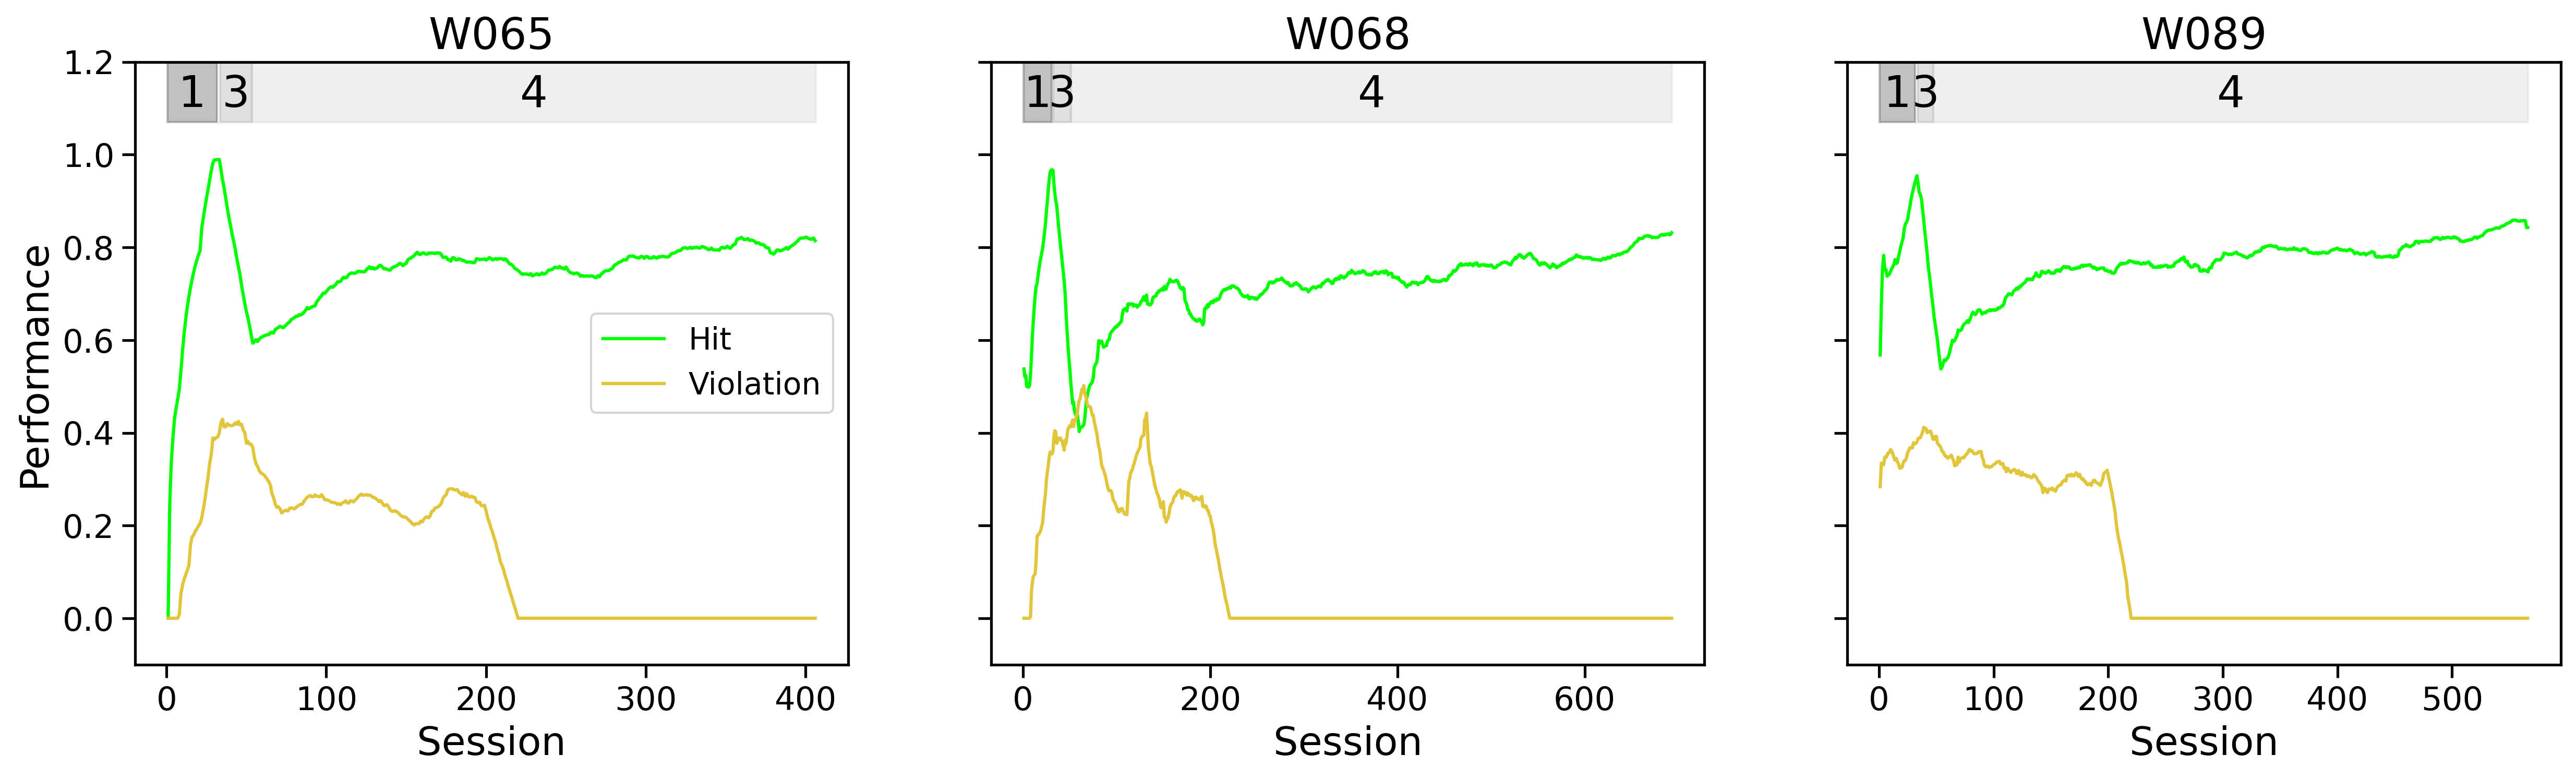

In [3]:
example_animals_df.head()

pal = sns.color_palette("gray", 4)
fig, ax = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for i, (animal, df) in enumerate(example_animals_df.groupby("animal_id", observed=True)):
    df = df.copy()
    df["hit_smoothed"] = df["hit_rate"].rolling(
        window=21, min_periods=1).mean()
    df["violation_smoothed"] = df["viol_rate"].rolling(
        window=21, min_periods=1).mean()

    sns.lineplot(
        x="session",
        y="hit_smoothed",
        data=df,
        color=HIT_COLOR,
        ax=ax[i],
        errorbar=None,
        label="Hit",
    )
    sns.lineplot(
        x="session",
        y="violation_smoothed",
        data=df,
        color=VIOLATION_COLOR,
        ax=ax[i],
        errorbar=None,
        label="Violation",
    )

    for stage in df["stage"].unique():
        if stage == 2:
            continue
        stage_df = df[df["stage"] == stage]
        ax[i].axvspan(
            xmin=stage_df["session"].min() - 0.5,
            xmax=stage_df["session"].max() + 0.5,
            ymin=0.9,
            ymax=1,
            alpha=0.3,
            color=pal[stage - 1],
        )
        ax[i].text(
            x=stage_df["session"].mean(),
            y=1.13,
            s=f"{int(stage)}",
            ha="center",
            va="center",
        )

    ax[i].set(ylabel="Performance", title=animal,
              xlabel="Session", ylim=(-0.1, 1.2))
    if i != 0:
        ax[i].get_legend().remove()

save_figure(fig, "suppS1a_example_animals")

## Panel B — Timeout state-machine schematic

Made in google drawings.

## Panel C — W089 hit-rate alignment (old vs new)

Session-average hit rate for W089 from the public dataset (orange dashed) and the reconstructed dataset (blue solid). Same comparison as the mega-fig `plot_hit_rates()` panel (without timeouts).


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS1c_hit_alignment.png')

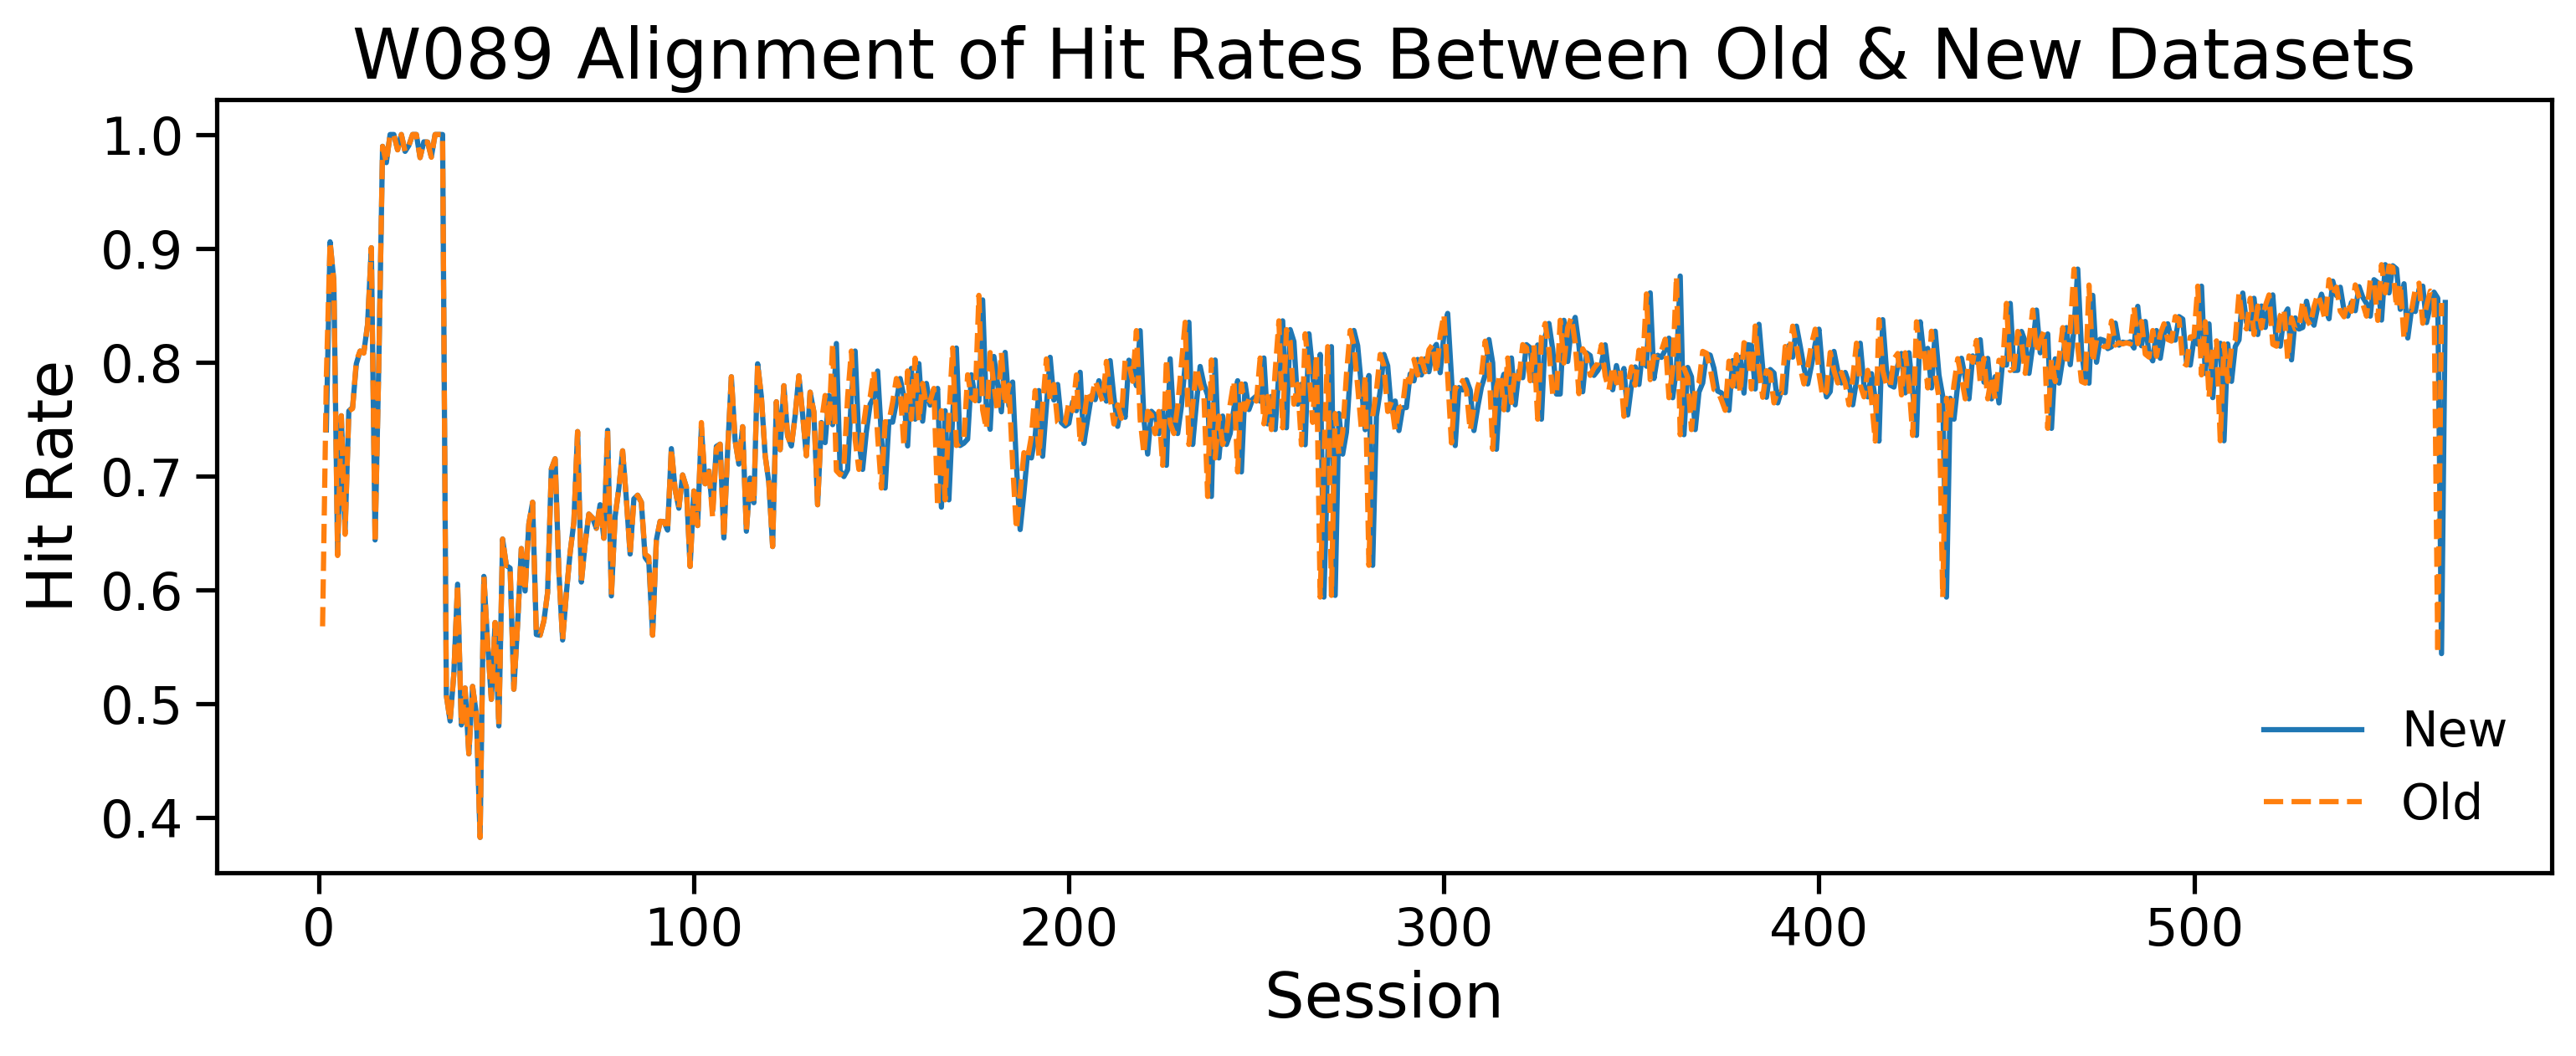

In [4]:
hit = alignment_curves.copy()
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(
    data=hit.query("source == 'new'"),
    x="session",
    y="hit_rate",
    ax=ax,
    color=NEW_DATASET_COLOR,
    label="New",
)
sns.lineplot(
    data=hit.query("source == 'old'"),
    x="session",
    y="hit_rate",
    ax=ax,
    color=OLD_DATASET_COLOR,
    linestyle="--",
    label="Old",
)
ax.set(
    title="W089 Alignment of Hit Rates Between Old & New Datasets",
    xlabel="Session",
    ylabel="Hit Rate",
)
ax.legend(frameon=False)
save_figure(fig, "suppS1c_hit_alignment")

## Panel D — W089 trial-count alignment (old vs new)

Max trial number per session for W089. Black dashed line marks session 200, after which the public table stopped tracking violations (trial counts in the reconstructed data are higher thereafter).


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS1d_trial_alignment.png')

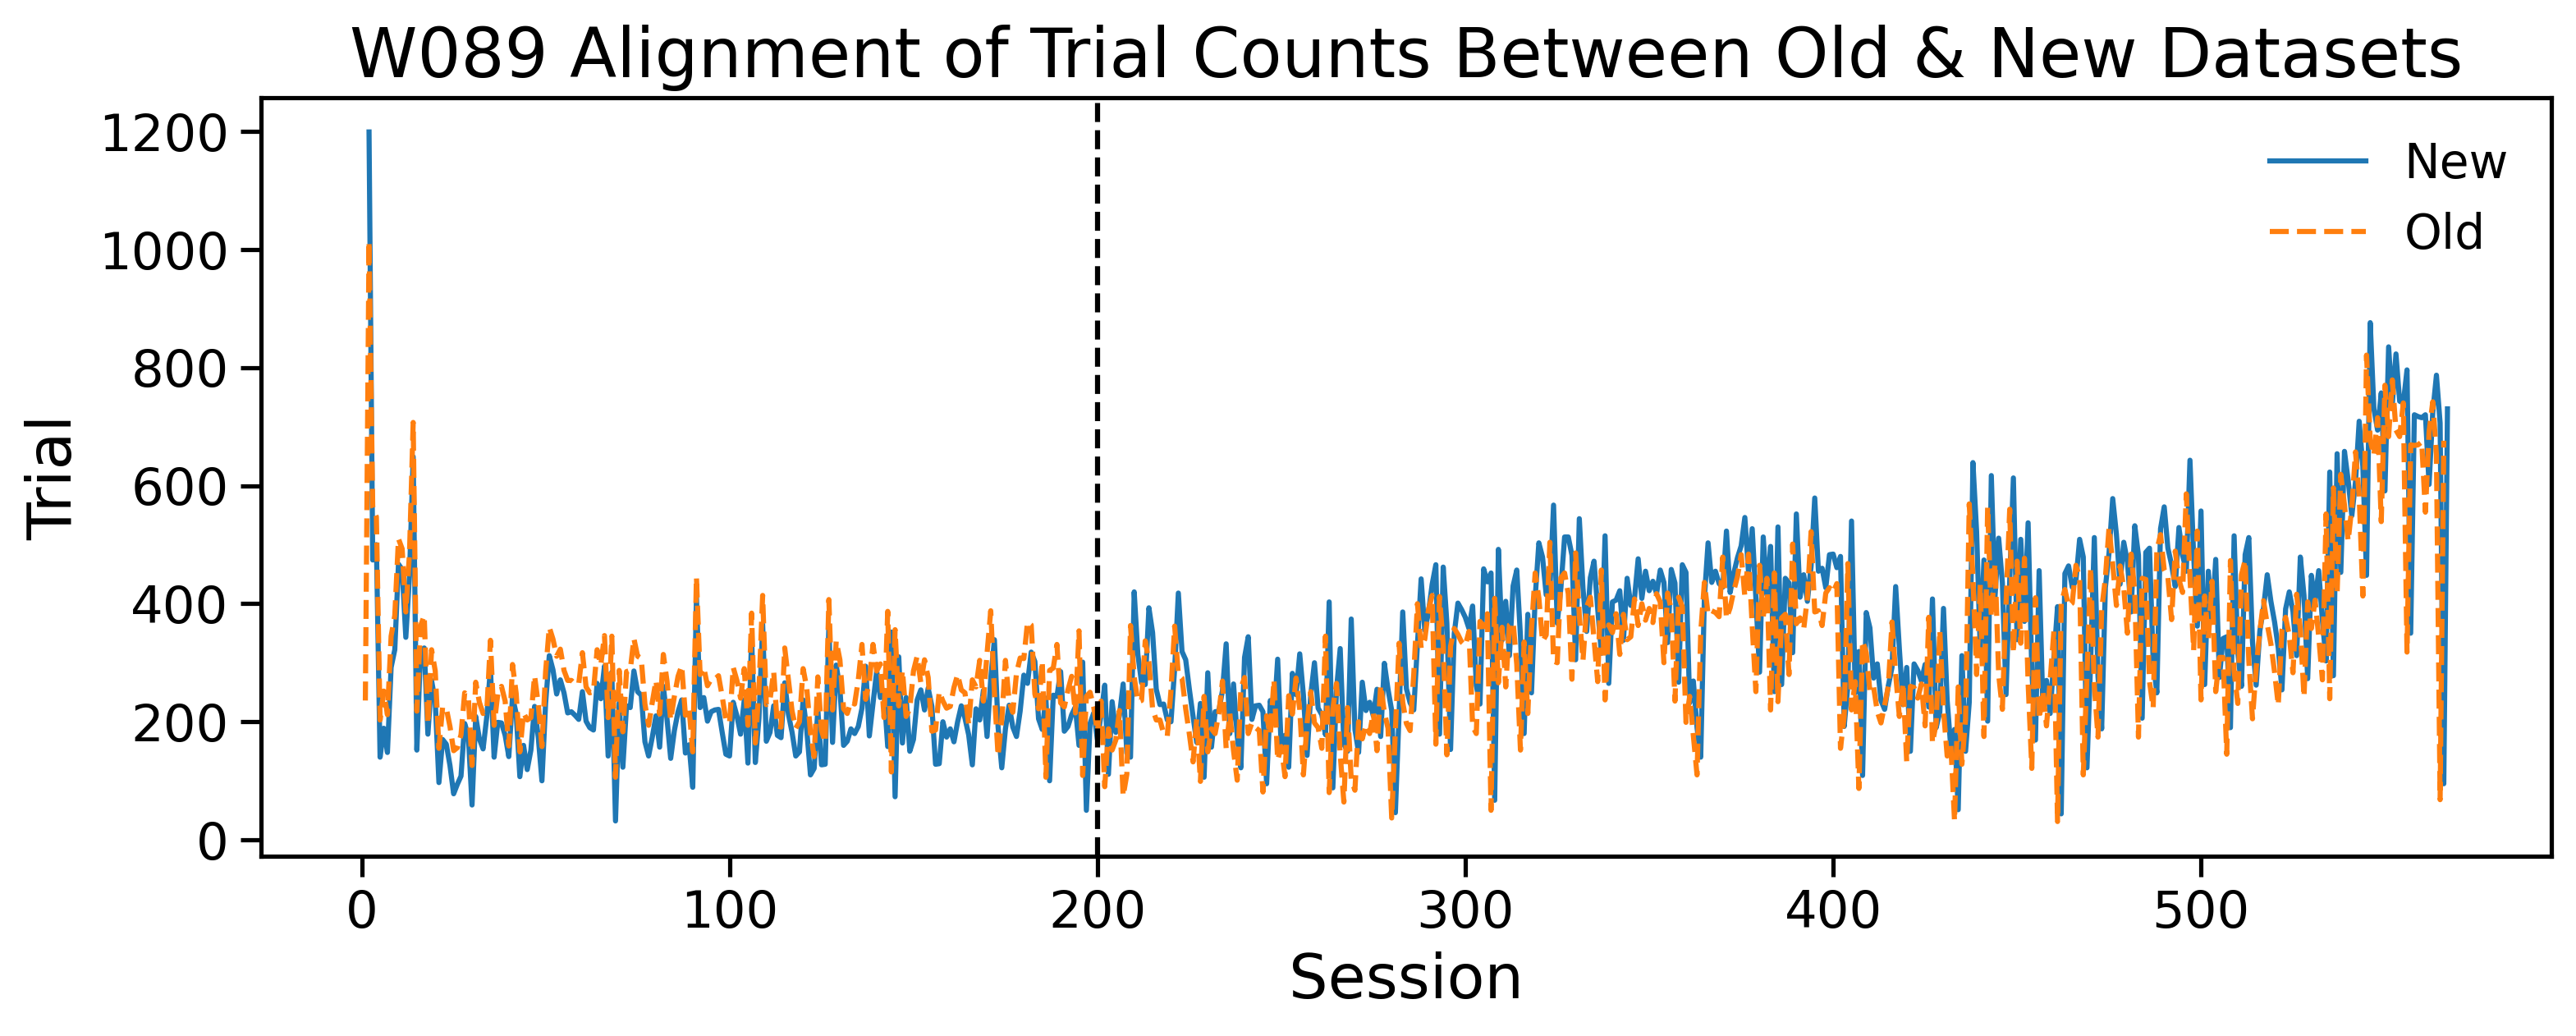

In [5]:
trials = alignment_curves.copy()
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(
    data=trials.query("source == 'new'"),
    x="session",
    y="n_trials",
    ax=ax,
    color=NEW_DATASET_COLOR,
    label="New",
)
sns.lineplot(
    data=trials.query("source == 'old'"),
    x="session",
    y="n_trials",
    ax=ax,
    color=OLD_DATASET_COLOR,
    linestyle="--",
    label="Old",
)
ax.axvline(200, color="k", linestyle="--", linewidth=1.5)
ax.set(
    title="W089 Alignment of Trial Counts Between Old & New Datasets",
    xlabel="Session",
    ylabel="Trial",
)
ax.legend(frameon=False)
save_figure(fig, "suppS1d_trial_alignment")

## Panel E — $\Delta$ number of sessions

Positive values: more sessions in the reconstructed (`new`) dataset than in the public (`old`) table.


,animal_id,delta_n_sessions
0,W051,14
1,W060,-6
2,W065,70
3,W066,-11
4,W068,-4
5,W072,2
6,W073,2
7,W074,-24
8,W075,86
9,W078,-13


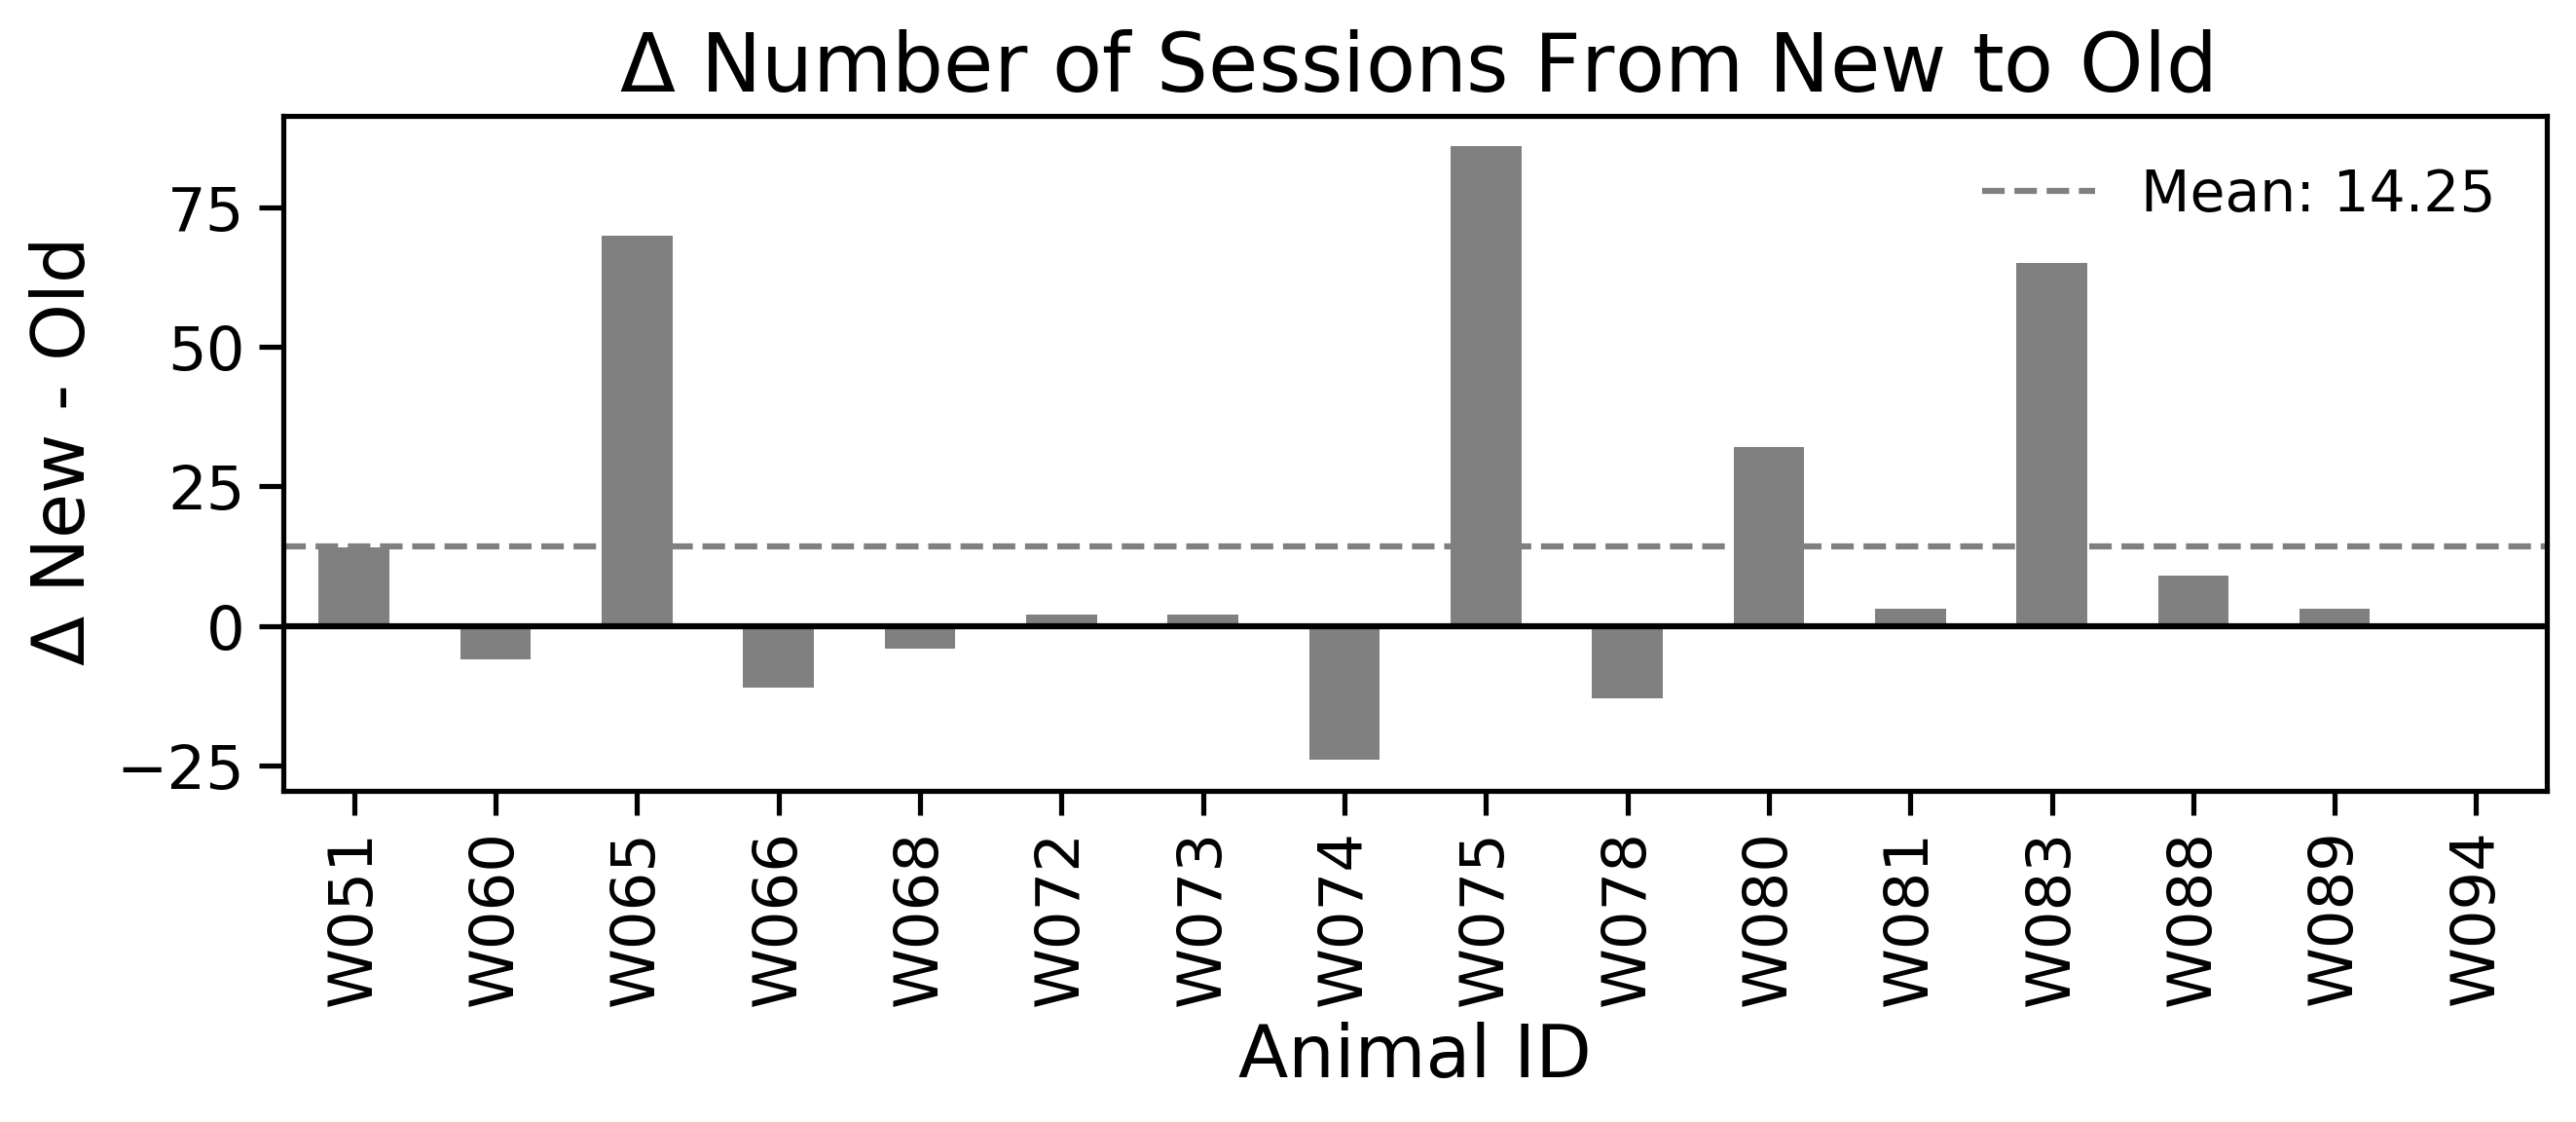

In [6]:
fig, ax = plt.subplots(figsize=(10, 3))
dd = deltas[["animal_id", "delta_n_sessions"]].copy()
dd.plot(
    x="animal_id",
    y="delta_n_sessions",
    kind="bar",
    ax=ax,
    legend=False,
    color=N_SESSION_COLOR,
)
ax.axhline(0, color="k")
ax.set(
    title=r"$\Delta$ Number of Sessions From New to Old",
    ylabel=r"$\Delta$ New - Old",
    xlabel="Animal ID",
)
mean_value = dd["delta_n_sessions"].mean()
ax.axhline(
    mean_value, color=N_SESSION_COLOR, linestyle="--", label=f"Mean: {mean_value:.2f}"
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:1], labels[:1], frameon=False)
save_figure(fig, "suppS1e_delta_sessions")
dd

## Panel F — $\Delta$ trials per session

`new_no_touts` minus `old`.


,animal_id,delta_n_trials_per_session
0,W051,11.706973
1,W060,11.152332
2,W065,-4.045431
3,W066,24.877713
4,W068,17.158896
5,W072,8.905013
6,W073,12.051261
7,W074,74.204519
8,W075,68.770646
9,W078,3.738512


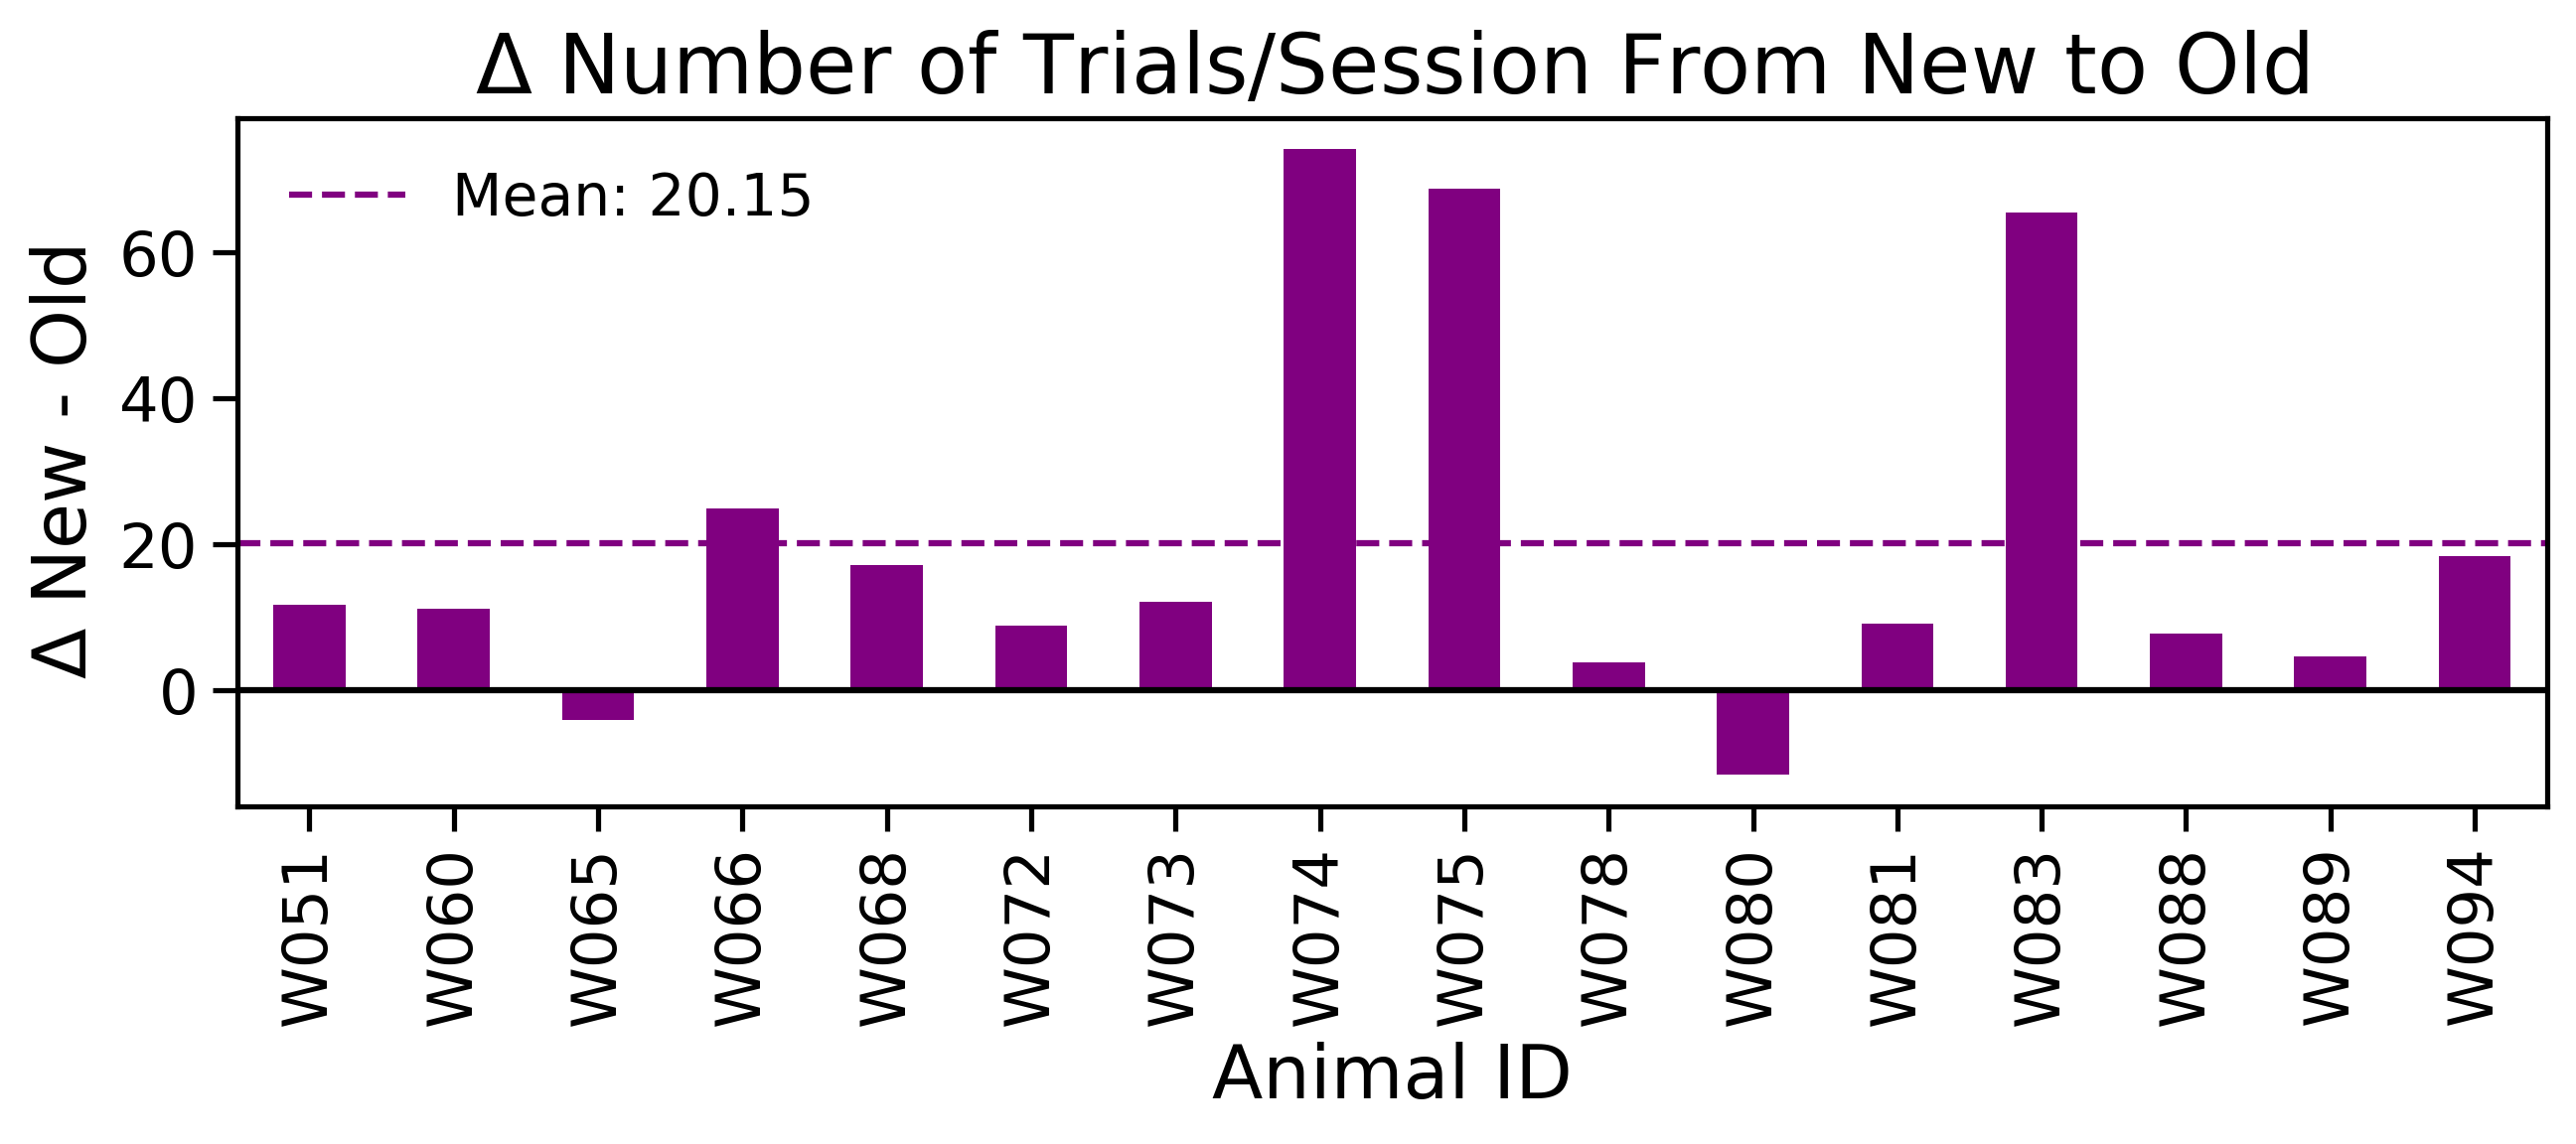

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
dd = deltas[["animal_id", "delta_n_trials_per_session"]].copy()
dd.plot(
    x="animal_id",
    y="delta_n_trials_per_session",
    kind="bar",
    ax=ax,
    legend=False,
    color=N_TRIAL_COLOR,
)
ax.axhline(0, color="k")
ax.set(
    title=r"$\Delta$ Number of Trials/Session From New to Old",
    ylabel=r"$\Delta$ New - Old",
    xlabel="Animal ID",
)
mean_value = dd["delta_n_trials_per_session"].mean()
ax.axhline(
    mean_value, color=N_TRIAL_COLOR, linestyle="--", label=f"Mean: {mean_value:.2f}"
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:1], labels[:1], frameon=False)
save_figure(fig, "suppS1f_delta_trials")
dd

## Panel G — $\Delta$ violation rate per session

`new_no_touts` minus `old`, scaled by 100 (percentage points), matching the submitted figure.


,animal_id,delta_session_avg_violation
0,W051,-0.558355
1,W060,-1.945241
2,W065,-2.163914
3,W066,-5.875654
4,W068,-3.544050
5,W072,-6.040816
6,W073,-5.212685
7,W074,-2.819353
8,W075,0.203096
9,W078,-0.815306


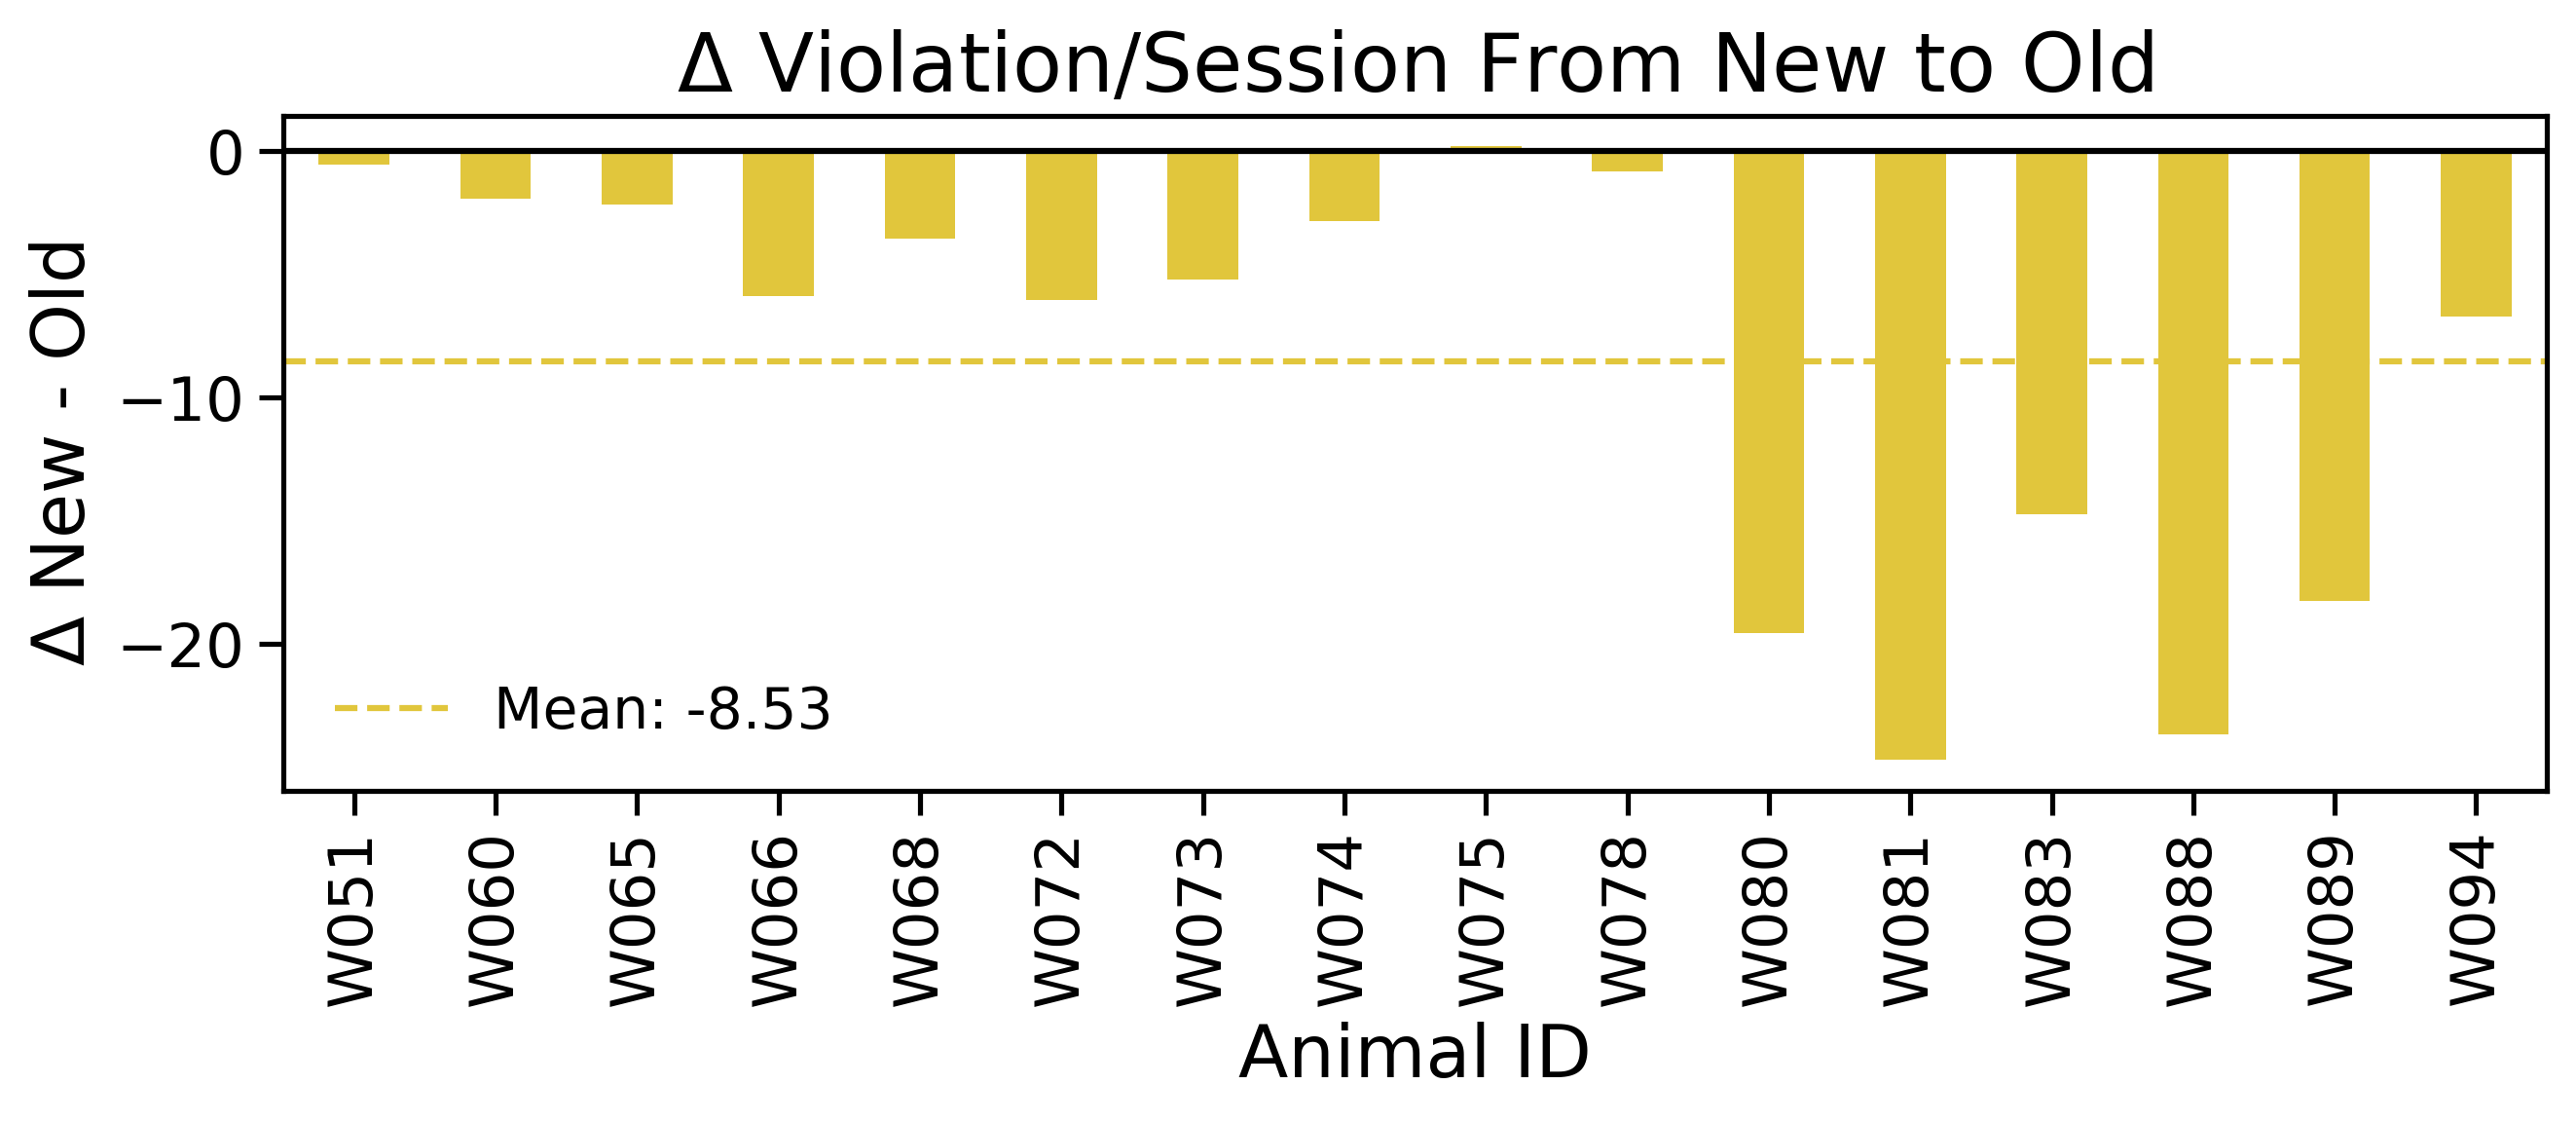

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))
dd = deltas[["animal_id", "delta_session_avg_violation"]].copy()
dd["delta_session_avg_violation"] = dd["delta_session_avg_violation"] * 100
dd.plot(
    x="animal_id",
    y="delta_session_avg_violation",
    kind="bar",
    ax=ax,
    legend=False,
    color=VIOLATION_COLOR,
)
ax.axhline(0, color="k")
ax.set(
    title=r"$\Delta$ Violation/Session From New to Old",
    ylabel=r"$\Delta$ New - Old",
    xlabel="Animal ID",
)
mean_value = dd["delta_session_avg_violation"].mean()
ax.axhline(
    mean_value, color=VIOLATION_COLOR, linestyle="--", label=f"Mean: {mean_value:.2f}"
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:1], labels[:1], frameon=False)
save_figure(fig, "suppS1g_delta_violations")
dd

## Dataset comparison stats

Printed values from the source notebook: session-averaged violation mean/std across `old`, `new_all`, and `new_match_old_viols`, plus reconstructed `new_all` trial and session counts (16 animals).


In [9]:
dataset_comparison

print(f"N trials: {dataset_counts['n_trials_new_all']}")
print(f"N sessions: {dataset_counts['n_sessions_new_all']}")

N trials: 2711970
N sessions: 9255
